### Open the data

In [1]:
import sys
import pandas as pd
from pathlib import Path
import geopandas as gpd
from sklearn.preprocessing import StandardScaler

sys.path.append("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/src")
from time_series.series_aligner import align_sensor_series


#Let's reproduce what Kalpan did. I will vary it slightly however. 
#i will apply clustering to the projected data. 

PROJECT_ROOT = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis"

DATA_DIR = Path(PROJECT_ROOT) / "data"

#The two data types parent dirs:
SATELLITE_DATA_DIR = DATA_DIR / "kriging_satellite"/"layers"
STREET_VIEW_DATA_DIR = DATA_DIR/"kriging_street_view"

#Paths dictionaries
satellite_data_dirs = {
    "ndvi":SATELLITE_DATA_DIR/"ndvi_grid.geojson",
    "ndbi":SATELLITE_DATA_DIR/"ndbi_grid.geojson",
    "impervious":SATELLITE_DATA_DIR/"nlcd_impervious_grid.geojson",
    "road_density":SATELLITE_DATA_DIR/"road_density_grid.geojson"
}

street_view_data_dirs ={
    "gvi":STREET_VIEW_DATA_DIR/"grid_aggregated_gvi.geojson",
    "facades":STREET_VIEW_DATA_DIR/"grid_aggregated_facade_area.geojson",
    "cars":STREET_VIEW_DATA_DIR/"grid_aggregated_n_cars.geojson",
    "sky_ratio":STREET_VIEW_DATA_DIR/"grid_aggregated_sky_ratio.geojson",
    "road_ratio":STREET_VIEW_DATA_DIR/"grid_aggregated_road_ratio.geojson"
}

#Ok, so now we open the gdfs

gdfs_satellite = {x:gpd.read_file(satellite_data_dirs[x]) for x in list(satellite_data_dirs.keys())}

gdfs_street_view = {x:gpd.read_file(street_view_data_dirs[x]) for x in list(street_view_data_dirs.keys())}





In [2]:
# Now the sensor data. 

SENSORS_DIR = DATA_DIR / "sensors"

#Here I am just going to copy the code in the K_means notebooks. 
sensor_csvs = {
    'Boston Carter Field':               SENSORS_DIR / 'boston_carter_field'         / 'boston_carter_field.csv',
    'Boston Gainsborough Parking Garage': SENSORS_DIR / 'boston_gainsborough_parking' / 'boston_gainsborough_parking.csv',
    'Boston Robinson Hall':              SENSORS_DIR / 'boston_robinson_hall'         / 'boston_robinson_hall.csv',
    'Boston West Village B':             SENSORS_DIR / 'boston_west_village_b'        / 'boston_west_village_b.csv',
    'Boston World Series Way':           SENSORS_DIR / 'boston_world_series_way'      / 'boston_world_series_way.csv',
}

sensor_data_frames = {x:pd.read_csv(sensor_csvs[x]) for x in list(sensor_csvs.keys())}

#Let's do this for the temperature. Te next step is to align the frames.
aligned_df, _ = align_sensor_series(
    sensor_dataframes = sensor_data_frames,
    variable_name = "temperature",
    time_column = "timestamp",
    sampling_interval = "1min",
    timestamp_tolerance = "15min"
)

#Get the mean temperatures between 3 and 4pm
sensor_temperatures_df = aligned_df.between_time("15:00", "16:00").mean()
sensor_locations_df = pd.read_csv(DATA_DIR/"spatial"/"data-1775857265051.csv")

sensor_names = list(sensor_csvs.keys())
sensor_name_map = {
    'Robinson Hall': 'Boston Robinson Hall',
    'West Village B': 'Boston West Village B',
    'Gainsborough Parking Garage': 'Boston Gainsborough Parking Garage',
    'Carter Field': 'Boston Carter Field',
    'World Series Way': 'Boston World Series Way',
    'World Series Way-2': 'Boston World Series Way',
}

#Map the ecohub locations to the canonic names we are using for the sensors. 
sensor_locations_df["ecohub_location"] = sensor_locations_df["ecohub_location"].apply(lambda x: sensor_name_map.get(x,x))

#This does 2 things: (1) gets the series "temperature" from the data frame, and (2) renames the column index to ecohub location. 
sensor_temperatures_df = sensor_temperatures_df.rename("temperature").reset_index().rename(columns={'index': 'ecohub_location'})

#Merge sensor_temperatures with the locations

final_sensor_df = pd.merge(
    sensor_locations_df,
    sensor_temperatures_df,
    on='ecohub_location',
    how='inner'
)

final_sensor_df


,moduleid,ecohub_location,ecohub_id,lat,lon,timestamp,temperature
0,864622040811271,Boston Robinson Hall,1.0,42.339189,-71.086522,NaN,28.198644
1,864622040844447,Boston West Village B,4.0,42.337650,-71.092381,NaN,22.676928
2,868050045473267,Boston Gainsborough Parking Garage,2.0,42.340394,-71.085079,NaN,28.377312
3,860111057320867,Boston Carter Field,NaN,42.339254,-71.084348,NaN,26.214514


In [3]:
def _ensure_grid_id(gdf):
    """
    Ensures that the index of the geodataframe is called grid_id.
    """
    if 'grid_id' in gdf.columns: return gdf.copy()
    if 'id'      in gdf.columns: return gdf.copy().rename(columns={'id': 'grid_id'})
    return gdf.reset_index(drop=False).rename(columns={'index': 'grid_id'})

def _pick_col(gdf, candidates):
    for c in candidates:
        if c in gdf.columns: return c
    raise ValueError(f'None of {candidates} in {list(gdf.columns)}')

sat_specs = [
    ('ndvi',         ['ndvi', 'ndvi_mean']),
    ('ndbi',         ['ndbi', 'ndbi_mean']),
    ('impervious',   ['impervious', 'nlcd_impervious']),
    ('road_density', ['road_density_km_km2', 'road_density']),
]
sv_specs = [
    ('gvi',        ['gvi_mean', 'gvi']),
    ('facades',    ['facade_area_mean', 'facade_area', 'facades']),
    ('cars',       ['n_cars_mean', 'n_cars', 'cars']),
    ('sky_ratio',  ['sky_ratio_mean', 'sky_ratio']),
    ('road_ratio', ['road_ratio_mean', 'road_ratio']),
]

base = _ensure_grid_id(gdfs_satellite['ndvi'])
base_crs = base.crs
grid_features = base[['grid_id', 'geometry']].copy()

for out_name, candidates in sat_specs:
    layer = _ensure_grid_id(gdfs_satellite[out_name]).to_crs(base_crs)
    col = _pick_col(layer, candidates)
    grid_features = grid_features.merge(
        layer[['grid_id', col]].rename(columns={col: out_name}), on='grid_id', how='left'
    )

for out_name, candidates in sv_specs:
    layer = _ensure_grid_id(gdfs_street_view[out_name]).to_crs(base_crs)
    col = _pick_col(layer, candidates)
    grid_features = grid_features.merge(
        layer[['grid_id', col]].rename(columns={col: out_name}), on='grid_id', how='left'
    )

# road_density NaNs = 0 (no road), SV NaNs = median
grid_features['road_density'] = grid_features['road_density'].fillna(0.0)
print(f'Grid cells: {len(grid_features)}')
print(f'NaN counts:\n{grid_features.drop(columns=["grid_id","geometry"]).isna().sum()}')



Grid cells: 900
NaN counts:
ndvi             0
ndbi             0
impervious       0
road_density     0
gvi             43
facades         43
cars            43
sky_ratio       43
road_ratio      43
dtype: int64


In [4]:
import numpy as np

# Prepare the same clustering features used in K_Means.ipynb.
# The intern's notebook referenced these log columns but did not create them in a clean run.
required_raw_cols = ['ndvi', 'ndbi', 'road_density', 'gvi', 'cars']
missing_raw_cols = [col for col in required_raw_cols if col not in grid_features.columns]
if missing_raw_cols:
    raise KeyError(f'Missing raw predictor columns: {missing_raw_cols}')

if 'road_density_log1p' not in grid_features.columns:
    grid_features['road_density_log1p'] = np.log1p(grid_features['road_density'].clip(lower=0.0))

if 'cars_log1p' not in grid_features.columns:
    grid_features['cars_log1p'] = np.log1p(grid_features['cars'].clip(lower=0.0))

predictor_cols_kmeans = [
    'ndvi', 'ndbi', 'road_density_log1p', 'gvi', 'cars_log1p'
]


#Fill with median. 
for col in predictor_cols_kmeans:
    if grid_features[col].isna().any():
        grid_features[col] = grid_features[col].fillna(grid_features[col].median())

print('KMeans/PCA predictor columns ready:')
print(predictor_cols_kmeans)
print('\nNaN counts after preparation:')
print(grid_features[predictor_cols_kmeans].isna().sum())


KMeans/PCA predictor columns ready:
['ndvi', 'ndbi', 'road_density_log1p', 'gvi', 'cars_log1p']

NaN counts after preparation:
ndvi                  0
ndbi                  0
road_density_log1p    0
gvi                   0
cars_log1p            0
dtype: int64


### PCA -> K-Means-> Visualizing the 2 groups

The silhouette score is 0.4334300755962162

Grid cells per cluster:
labels
0    310
1    590
Name: count, dtype: int64


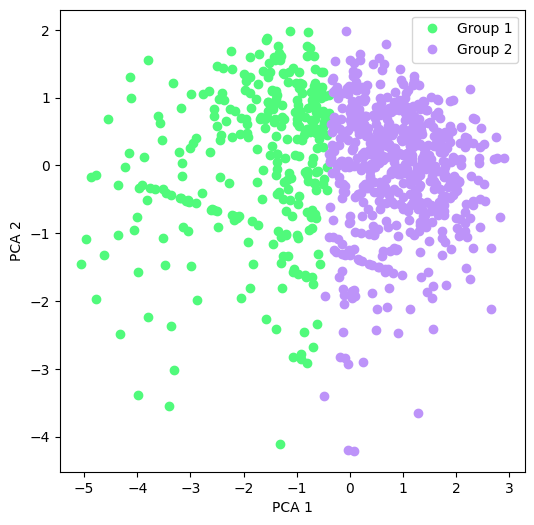

In [5]:
from tools.pca import pca_transform_data
import matplotlib.pyplot as plt

#If I remember correctly we have to first standardize the data, which basically means (x - mean)/std
scaler = StandardScaler()
feature_table = scaler.fit_transform(grid_features[predictor_cols_kmeans])

#Now what we can do is apply PCA
pca_coords = pca_transform_data(feature_table, n_components=2, random_state = 42)
grid_features["pca_1"] = pca_coords[:, 0]
grid_features["pca_2"] = pca_coords[:, 1]

#Let's apply k_means
from tools.kmeans import apply_kmeans

labels, centroids, score = apply_kmeans(pca_coords)

print(f"The silhouette score is {score}")
grid_features["labels"] = labels
print("\nGrid cells per cluster:")
print(grid_features["labels"].value_counts().sort_index())

COLOR_1 = "#50FA7B"
COLOR_2 = "#BD93F9"

label_1_data = pca_coords[labels == 0]
label_2_data = pca_coords[labels == 1]

plt.figure(figsize = (6,6))
plt.plot(label_1_data[:,0], label_1_data[:,1], marker = "o", color = COLOR_1, linestyle="None", label = "Group 1")
plt.plot(label_2_data[:,0], label_2_data[:,1], color = COLOR_2, marker = "o", linestyle="none", label = "Group 2")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()


Text(0.5, 1.0, 'Labelled grid cells')

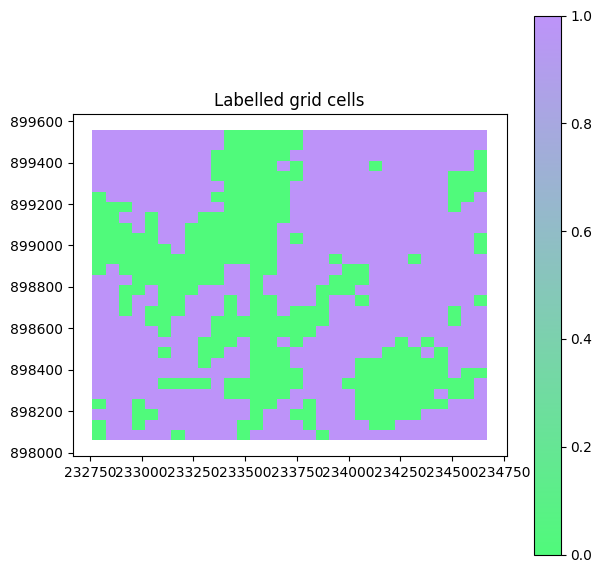

In [6]:
from matplotlib.colors import LinearSegmentedColormap
cluster_cmap = LinearSegmentedColormap.from_list(
    "cluster_cmap",
    [COLOR_1, COLOR_2]
)

fig, ax = plt.subplots(1,1, figsize = (7,7))
grid_features.plot(ax = ax, column = "labels", legend = True, cmap = cluster_cmap)
ax.set_title("Labelled grid cells")


### Map sensors to cluster regions

In [7]:
sensor_data_path = DATA_DIR / "spatial" / "sensor_locations.json"
sensor_locations_df = pd.read_json(sensor_data_path)

#Open the sensor locations
sensor_locations_gdf = gpd.GeoDataFrame(
    sensor_locations_df,
    geometry=gpd.points_from_xy(
        sensor_locations_df["longitude"],
        sensor_locations_df["latitude"],
    ),
    crs="EPSG:4326",
)

#Rename column of the sensor_tempereature before merging
sensor_temperatures_for_merge = sensor_temperatures_df.rename(
    columns={"ecohub_location": "sensor_name"}
)

#At this point the df contains position and temperature
sensor_locations_gdf = sensor_locations_gdf.merge(
    sensor_temperatures_for_merge,
    on="sensor_name",
    how="inner",
)


#Ensure same CRS
sensor_locations_gdf = sensor_locations_gdf.to_crs(grid_features.crs)
grid_features["grid_index"] = grid_features.index

grid_features["pca_1"] = pca_coords[:, 0]
grid_features["pca_2"] = pca_coords[:, 1]

sensor_with_grid = gpd.sjoin(
    sensor_locations_gdf,
    grid_features[["grid_index", "grid_id", "labels", "geometry", "pca_1", "pca_2"]],
    how="left",
    predicate="within",
)

train_df = sensor_with_grid[
    ["temperature", "labels", "pca_1", "pca_2"]
].dropna().copy()

cluster_counts = train_df["labels"].value_counts()
cluster_counts = cluster_counts.sort_index()
print(cluster_counts)


labels
0    2
1    3
Name: count, dtype: int64


### Regression + Krigging considering clusters.

In [29]:
from kriging.ridge_regression import train_ridge, ridge_predict

predictors_with_cluster = ["pca_1", "pca_2", "labels"]

global_cluster_model = train_ridge(
    X=train_df[predictors_with_cluster].to_numpy(float),
    y=train_df["temperature"],
    alpha=1.0,
    fit_intercept=True,
)

predictors_with_cluster = ["pca_1", "pca_2", "labels"]

grid_features["predicted_temperature_ridge_cluster"] = ridge_predict(
    global_cluster_model,
    grid_features[predictors_with_cluster].to_numpy(float),
)


train_df["predicted_temperature"] = ridge_predict(
    global_cluster_model,
    train_df[predictors_with_cluster].to_numpy(float),
)


global_cluster_model

{'model': 'ridge',
 'alpha': 1.0,
 'fit_intercept': True,
 'intercept': 25.970935242326224,
 'coefficients': [1.0997920690537768,
  -1.0144120396111813,
  -0.9887722580861863],
 'n_features': 3,
 'n_samples': 5,
 'feature_names': None,
 'score_r2': 0.5829522988489411,
 'training_predictions': [24.248084759692805,
  25.27953424267247,
  25.638715282477236,
  28.095728523165384,
  26.32611106424321]}

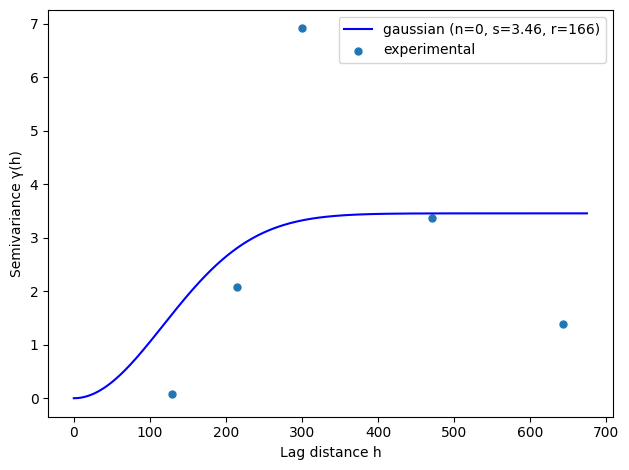

In [30]:


train_df["residual"] = train_df["temperature"] - train_df["predicted_temperature"]

sensor_residuals_gdf = sensor_with_grid.copy()

sensor_residuals_gdf["x"] = sensor_residuals_gdf.geometry.x
sensor_residuals_gdf["y"] = sensor_residuals_gdf.geometry.y

from kriging.variogram_training import fit_variogram_model, plot_variogram_fit

res_points = list(zip(
    sensor_residuals_gdf["x"],
    sensor_residuals_gdf["y"],
))

res_values = train_df["residual"].to_list()

residual_variogram_model = fit_variogram_model(
    points=res_points,
    values=res_values,
)

plot_variogram_fit(residual_variogram_model)

In [31]:
from kriging.variogram_training import ordinary_kriging_predict

query_points = [
    (geom.centroid.x, geom.centroid.y)
    for geom in grid_features.geometry
]

estimated_residuals = ordinary_kriging_predict(
    points=res_points,
    values=res_values,
    fit=residual_variogram_model,
    query_points=query_points,
)

grid_features["estimated_residual"] = estimated_residuals

grid_features["final_temperature_cluster_kriging"] = (
    grid_features["predicted_temperature_ridge_cluster"]
    + grid_features["estimated_residual"]
)

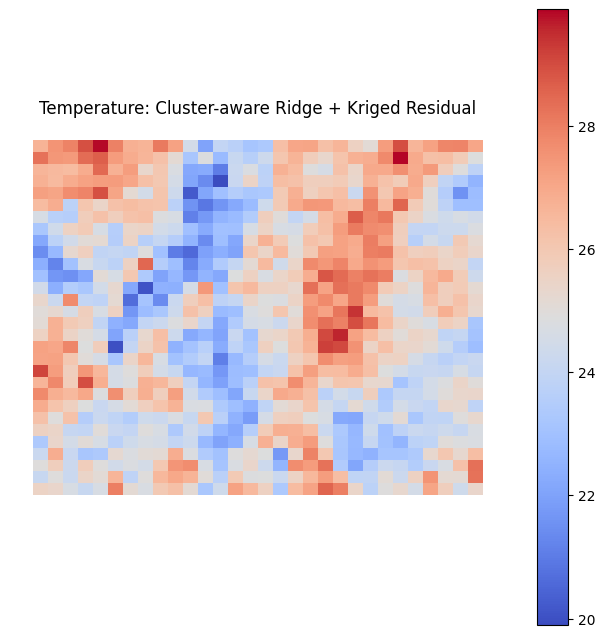

In [32]:
COLOR_1 = "#6272a4"
COLOR_2 = "#ff5555"
my_cmap = LinearSegmentedColormap.from_list(
    "cluster_cmap",
    [COLOR_1, COLOR_2]
)

fig, ax = plt.subplots(figsize=(8, 8))

grid_features.plot(
    column="final_temperature_cluster_kriging",
    cmap="coolwarm",
    legend=True,
    ax=ax,
)

ax.set_axis_off()
ax.set_title("Temperature: Cluster-aware Ridge + Kriged Residual")
plt.show()

### No-cluster ridge + kriging case

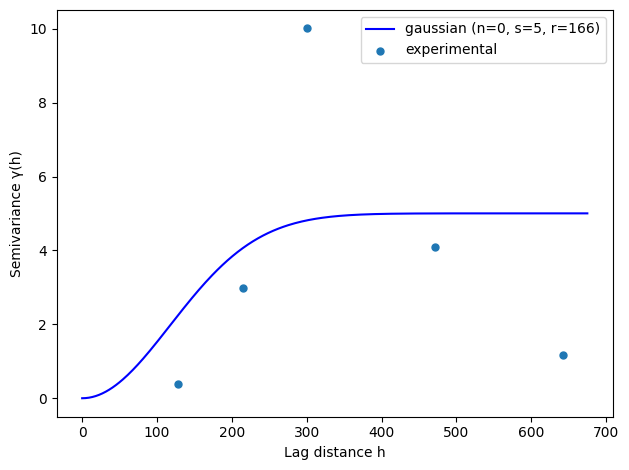

In [33]:
predictors = ["pca_1", "pca_2"]

global_model = train_ridge(
    X=train_df[predictors].to_numpy(float),
    y=train_df["temperature"],
    alpha=1.0,
    fit_intercept=True,
)

# Prediction on every grid cell using the no-cluster ridge model.
grid_features["predicted_temperature_ridge_no_cluster"] = ridge_predict(
    global_model,
    grid_features[["pca_1", "pca_2"]].to_numpy(float),
)

# Prediction at the sensor locations using the no-cluster ridge model.
train_df["predicted_temperature_no_cluster"] = ridge_predict(
    global_model,
    train_df[["pca_1", "pca_2"]].to_numpy(float),
)

# Residuals at sensors for the no-cluster case.
train_df["residual_no_cluster"] = train_df["temperature"] - train_df["predicted_temperature_no_cluster"]

# Use the same sensor rows as train_df, so coordinates and residuals match.
valid_sensor_index = train_df.index
sensor_points_for_kriging = sensor_with_grid.loc[valid_sensor_index]
sensor_points_for_kriging = sensor_points_for_kriging.copy()

sensor_points_for_kriging["x"] = sensor_points_for_kriging.geometry.x
sensor_points_for_kriging["y"] = sensor_points_for_kriging.geometry.y

res_points_no_cluster = list(zip(
    sensor_points_for_kriging["x"],
    sensor_points_for_kriging["y"],
))

res_values_no_cluster = train_df["residual_no_cluster"].to_list()

residual_variogram_model_no_cluster = fit_variogram_model(
    points=res_points_no_cluster,
    values=res_values_no_cluster,
)

plot_variogram_fit(residual_variogram_model_no_cluster)

estimated_residuals_no_cluster = ordinary_kriging_predict(
    points=res_points_no_cluster,
    values=res_values_no_cluster,
    fit=residual_variogram_model_no_cluster,
    query_points=query_points,
)

grid_features["estimated_residual_no_cluster"] = estimated_residuals_no_cluster

grid_features["final_temperature_no_cluster_kriging"] = (
    grid_features["predicted_temperature_ridge_no_cluster"]
    + grid_features["estimated_residual_no_cluster"]
)


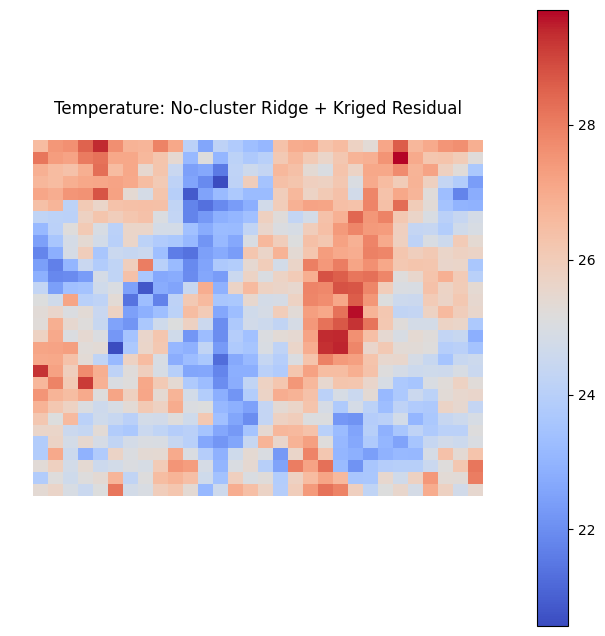

In [34]:
fig, ax = plt.subplots(figsize=(8, 8))

grid_features.plot(
    column="final_temperature_no_cluster_kriging",
    cmap="coolwarm",
    legend=True,
    ax=ax,
)

ax.set_axis_off()
ax.set_title("Temperature: No-cluster Ridge + Kriged Residual")
plt.show()


### Compare no-cluster and cluster-aware cases

In [35]:
# Sensor-level error comparison before kriging.
train_df["residual_cluster"] = train_df["temperature"] - train_df["predicted_temperature"]

rmse_no_cluster = np.sqrt(np.mean(train_df["residual_no_cluster"] ** 2))
rmse_cluster = np.sqrt(np.mean(train_df["residual_cluster"] ** 2))

print("No-cluster ridge R2:", global_model["score_r2"])
print("Cluster-aware ridge R2:", global_cluster_model["score_r2"])
print("No-cluster sensor RMSE:", rmse_no_cluster)
print("Cluster-aware sensor RMSE:", rmse_cluster)
print("RMSE improvement:", rmse_no_cluster - rmse_cluster)

# Grid-cell difference after ridge + kriging.
grid_features["temperature_difference_cluster_minus_no_cluster"] = (
    grid_features["final_temperature_cluster_kriging"]
    - grid_features["final_temperature_no_cluster_kriging"]
)

difference_values = grid_features["temperature_difference_cluster_minus_no_cluster"]

print("\nDifference summary: cluster-aware minus no-cluster")
print("min:", difference_values.min())
print("mean:", difference_values.mean())
print("max:", difference_values.max())
print("std:", difference_values.std())


No-cluster ridge R2: 0.45790525408120064
Cluster-aware ridge R2: 0.5829522988489411
No-cluster sensor RMSE: 1.6487218551275
Cluster-aware sensor RMSE: 1.4461144365203762
RMSE improvement: 0.20260741860712383

Difference summary: cluster-aware minus no-cluster
min: -0.7913941801657494
mean: -0.07279483866941557
max: 0.6809216976909731
std: 0.2827301883310434


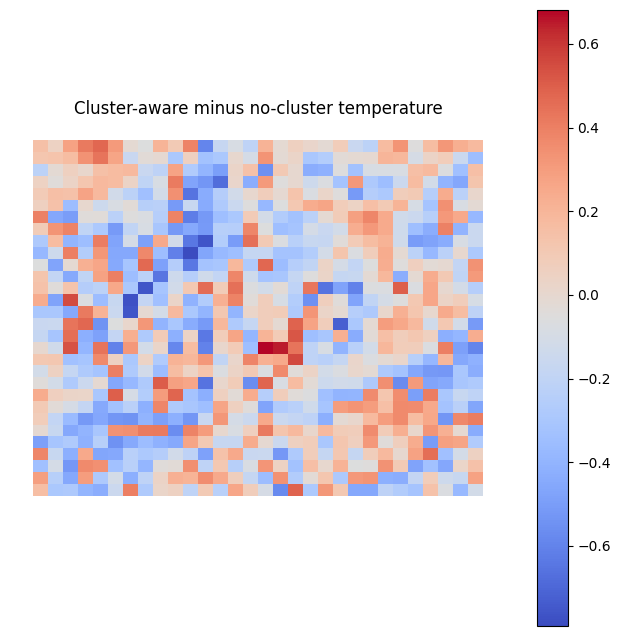

In [36]:
fig, ax = plt.subplots(figsize=(8, 8))

grid_features.plot(
    column="temperature_difference_cluster_minus_no_cluster",
    cmap="coolwarm",
    legend=True,
    ax=ax,
)

ax.set_axis_off()
ax.set_title("Cluster-aware minus no-cluster temperature")
plt.show()


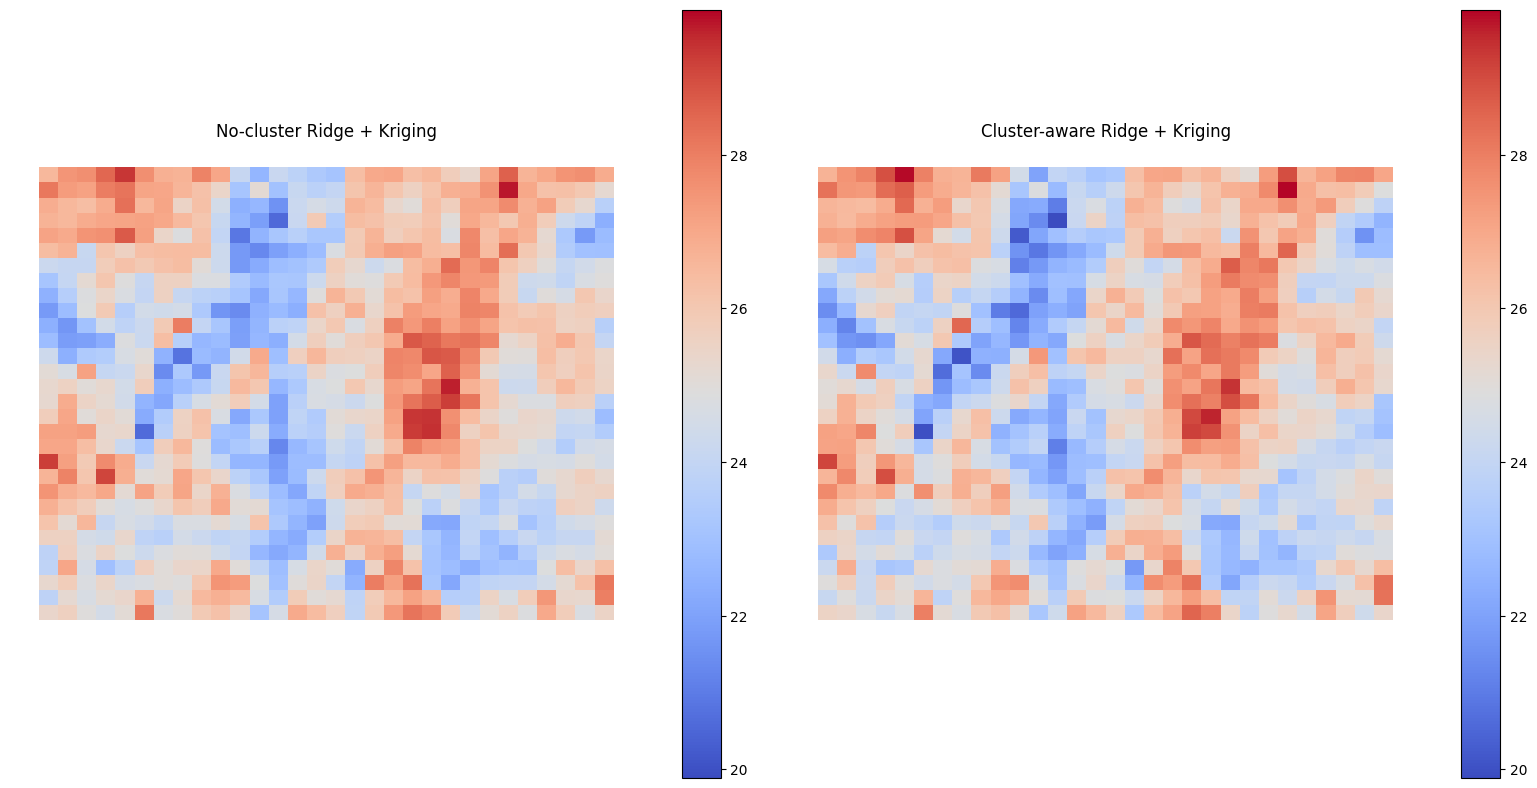

In [37]:
no_cluster_values = grid_features["final_temperature_no_cluster_kriging"]
cluster_values = grid_features["final_temperature_cluster_kriging"]

common_min = min(no_cluster_values.min(), cluster_values.min())
common_max = max(no_cluster_values.max(), cluster_values.max())

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

grid_features.plot(
    column="final_temperature_no_cluster_kriging",
    cmap="coolwarm",
    legend=True,
    ax=axes[0],
    vmin=common_min,
    vmax=common_max,
)

grid_features.plot(
    column="final_temperature_cluster_kriging",
    cmap="coolwarm",
    legend=True,
    ax=axes[1],
    vmin=common_min,
    vmax=common_max,
)

axes[0].set_axis_off()
axes[0].set_title("No-cluster Ridge + Kriging")

axes[1].set_axis_off()
axes[1].set_title("Cluster-aware Ridge + Kriging")

plt.tight_layout()
plt.show()


In [ ]:
### export labelled_lattice_cluster.geojson

### 